# Численные методы решения двухточечных краевых задач

## Разностные схемы со специальными аппроксимациями

### Случай переменного коэффициента диффузии

Вернемся к краевой задаче

$$
-(k(x)u'(x))'+q(x)u(x)=f(x),\quad a<x<b, \tag{1}
$$

$$
u(a)=u_a,\quad u(b)=u_b. \tag{2}
$$

Пусть $k(x)\geqslant k_0>0$ и $q(x)\geqslant0$. По сравнению со случаем $k\equiv1$ здесь нужно выбрать аппроксимацию производной потока $w(x)=-k(x)u'(x)$. На равномерной сетке $x_i=a+ih$, $i=0,\ldots,N$, при $N\geqslant2$ с шагом $h=(b-a)/N$ обозначим $x_{i+1/2}=(x_i+x_{i+1})/2$ и $k_{i+1/2}=k(x_{i+1/2})$. При $1\leqslant i\leqslant N-1$ аппроксимируем $w'(x_i)$ формулой

$$
w'(x_i)\approx\frac{w(x_{i+1/2})-w(x_{i-1/2})}{h}. \tag{3}
$$

Для потоков в соседних полуцелых узлах используем формулы

$$
w(x_{i+1/2})\approx-k_{i+1/2}\frac{u(x_{i+1})-u(x_i)}{h}, \tag{4}
$$

$$
w(x_{i-1/2})\approx-k_{i-1/2}\frac{u(x_i)-u(x_{i-1})}{h}. \tag{5}
$$

Отсюда

$$
-(ku')'(x_i)\approx-\frac{1}{h}\left(k_{i+1/2}\frac{u(x_{i+1})-u(x_i)}{h}
-k_{i-1/2}\frac{u(x_i)-u(x_{i-1})}{h}\right). \tag{6}
$$

**Определение 1 (консервативная разностная схема).** Диффузионный член аппроксимируется разностью численных потоков. В соседние уравнения один и тот же поток через общую грань входит с противоположными знаками. При $u_i=u^h(x_i)$, $q_i=q(x_i)$ и $f_i=f(x_i)$ положим

$$
L^h[u^h](x_i)=
-\frac{1}{h}\left(k_{i+1/2}\frac{u_{i+1}-u_i}{h}-k_{i-1/2}\frac{u_i-u_{i-1}}{h}\right)+q_i u_i. \tag{7}
$$

Сеточные уравнения имеют вид

$$
L^h[u^h](x_i)=f_i,\quad 1\leqslant i\leqslant N-1,\quad u_0=u_a,\quad u_N=u_b. \tag{8}
$$

Умножив внутренние уравнения на $h^2$, получим трехдиагональную систему. Коэффициенты $a_i,b_i,c_i$ при $u_{i-1},u_i,u_{i+1}$ удовлетворяют условиям на знаки, используемым в дискретном принципе максимума,

$$
a_i<0,\quad c_i<0,\quad b_i>0,\quad a_i+b_i+c_i\geqslant0. \tag{9}
$$

**Утверждение 1 (принцип максимума и разрешимость).** Для трехдиагональной системы с условиями (9) из неположительности правых частей и краевых значений следует неположительность всех узловых значений. В частности, система с условиями Дирихле имеет единственное решение при любых данных.

**Доказательство.** В самом правом узле, в котором достигается положительный максимум, имеем $u_{i-1}\leqslant u_i$ и $u_{i+1}<u_i$. Поэтому левая часть уравнения строго больше $(a_i+b_i+c_i)u_i\geqslant0$. Получили противоречие. Применив результат к решению однородной задачи и к его отрицанию, получим единственность. Существование следует из того, что система квадратная. $\square$

Для коэффициентов $a_i=-k_{i-1/2}$, $b_i=k_{i-1/2}+k_{i+1/2}+h^2q_i$ и $c_i=-k_{i+1/2}$ выполняется $a_i+b_i+c_i=h^2q_i\geqslant0$. Схема устойчива в норме максимума с оценкой, не зависящей от шага. Ниже это показано и для неравномерной сетки. Если $k\in C^3[a,b]$ и $q,f\in C^2[a,b]$, то $u\in C^4[a,b]$. Разложение Тейлора в каждом полуцелом узле дает погрешность потока с главным членом, пропорциональным $h^2ku'''$, и остатком $O(h^3)$. Разность главных членов на соседних гранях имеет порядок $O(h^3)$, поэтому невязка и максимальная узловая погрешность имеют порядок $O(h^2)$.

Можно поступить иначе. Если раскрыть производную $(ku')'=ku''+k'u'$, получим аппроксимацию

$$
k(x_i)\frac{u(x_{i-1})-2u(x_i)+u(x_{i+1})}{h^2}
+k'(x_i)\frac{u(x_{i+1})-u(x_{i-1})}{2h}. \tag{10}
$$

Соответствующий оператор имеет вид

$$
L^h[u^h](x_i)=-k(x_i)\frac{u_{i-1}-2u_i+u_{i+1}}{h^2}
-k'(x_i)\frac{u_{i+1}-u_{i-1}}{2h}+q_i u_i. \tag{11}
$$

После умножения на $h^2$ коэффициенты сеточной системы равны

$$
\begin{aligned}
a_i&=-k(x_i)+\tfrac h2 k'(x_i),\\
b_i&=2k(x_i)+h^2q_i,\\
c_i&=-k(x_i)-\tfrac h2 k'(x_i).
\end{aligned} \tag{12}
$$

Оба внедиагональных коэффициента строго отрицательны тогда и только тогда, когда

$$
h\max_{1\leqslant i\leqslant N-1}\frac{|k'(x_i)|}{k(x_i)}<2. \tag{13}
$$

При (13) выполнены условия (9). Если $k$ меняется резко, это условие может потребовать очень малого шага. В потоковой аппроксимации (7) нужные знаки сохраняются при любом шаге.

### Случай неравномерной сетки

Пусть $h_i=x_i-x_{i-1}$, $h_{\max}=\max_i h_i$, а $h_{i+1/2}=x_{i+1/2}-x_{i-1/2}=(h_i+h_{i+1})/2$ во внутреннем узле. Заменяя $h$ в (3), (4) и (5) величинами $h_{i+1/2}$, $h_{i+1}$ и $h_i$ соответственно, получаем

$$
L^h[u^h](x_i)=
-\frac{1}{h_{i+1/2}}\left(k_{i+1/2}\frac{u_{i+1}-u_i}{h_{i+1}}
-k_{i-1/2}\frac{u_i-u_{i-1}}{h_i}\right)+q_i u_i. \tag{14}
$$

Условия (9) сохраняются. Для проверки устойчивости возьмем решение $z^h$ неравномерной схемы с $q=0$, единичной правой частью и нулевыми краевыми значениями. По утверждению 1, $z^h\geqslant0$. Его численные потоки возрастают на $h_{i+1/2}$ в каждом внутреннем узле, а их взвешенная сумма с положительными весами $h_{i+1}/k_{i+1/2}$ равна нулю из-за краевых условий. Поэтому модуль каждого потока не превосходит $b-a$, и суммирование приращений дает $\|z^h\|_\infty\leqslant (b-a)^2/k_0$. Сравнение $u^h$ и $-u^h$ с $\max\{|u_a|,|u_b|\}+\max_i|f_i|\,z^h$ дает оценку, не зависящую от сетки. По линейности та же оценка применима к возмущениям данных.

При той же гладкости, что и в случае равномерной сетки, узловая невязка имеет порядок $O(h_{\max}^2)$, если $\max_i|h_{i+1}-h_i|=O(h_{\max}^2)$. Действительно, главный член, связанный с асимметрией разности потоков, и разность погрешностей двух потоков после деления на $h_{i+1/2}$ имеют порядок $O(|h_{i+1}-h_i|+h_{\max}^2)$. Из устойчивости следует сходимость второго порядка в максимальной узловой норме.

### Противопоточные разности

При переносе тепла в движущейся среде в уравнении появляется член конвекции,

$$
-(ku')'+vu'+qu=f. \tag{15}
$$

Здесь $v(x)$ пропорциональна скорости потока. Центральная аппроксимация добавляет к (7) слагаемое

$$
v_i\frac{u_{i+1}-u_{i-1}}{2h},\quad v_i=v(x_i). \tag{16}
$$

После умножения на $h^2$ получаем следующие коэффициенты внутренних уравнений,

$$
\begin{aligned}
a_i&=-k_{i-1/2}-\tfrac h2v_i,\\
b_i&=k_{i-1/2}+k_{i+1/2}+h^2q_i,\\
c_i&=-k_{i+1/2}+\tfrac h2v_i .
\end{aligned} \tag{17}
$$

Точное условие строгой отрицательности внедиагональных коэффициентов имеет вид $-2k_{i-1/2}<hv_i<2k_{i+1/2}$. Удобное достаточное условие имеет вид

$$
h|v_i|<2\min\{k_{i-1/2},k_{i+1/2}\}\quad\text{во всех внутренних узлах}. \tag{18}
$$

При больших скоростях это условие может потребовать малого шага.

**Определение 2 (противопоточная разность).** Выбираем одностороннюю разность со стороны набегающего потока,

$$
v_i u'(x_i)\approx v_i^+\frac{u(x_i)-u(x_{i-1})}{h}
+v_i^-\frac{u(x_{i+1})-u(x_i)}{h}, \tag{19}
$$

где

$$
v_i^+=\max\{v_i,0\},\quad v_i^-=\min\{v_i,0\}. \tag{20}
$$

При $v_i>0$ используем левую разность, а при $v_i<0$ — правую. Это дает

$$
\begin{aligned}
a_i&=-k_{i-1/2}-hv_i^+,\\
b_i&=k_{i-1/2}+k_{i+1/2}+h(v_i^+-v_i^-)+h^2q_i,\\
c_i&=-k_{i+1/2}+hv_i^- .
\end{aligned} \tag{21}
$$

Поскольку $a_i+b_i+c_i=h^2q_i$, принцип максимума выполняется при любом шаге. Для гладких решений противопоточная аппроксимация члена конвекции в общем случае имеет первый порядок.

### Случай разрывных коэффициентов

В неоднородных средах коэффициенты уравнения могут быть разрывными. Пусть $k,q,f$ ограничены, кусочно непрерывны и имеют конечное число скачков внутри $(a,b)$. Вне точек разрыва $k\geqslant k_0>0$ и $q\geqslant0$.

**Определение 3 (решение с условиями сопряжения).** Решение $u$ непрерывно на $[a,b]$, удовлетворяет (2) и дифференцируемо между точками разрыва. Поток $w=-ku'$ непрерывно продолжается через каждую границу раздела и между точками разрыва удовлетворяет уравнению

$$
w'(x)+q(x)u(x)=f(x). \tag{22}
$$

Условия описывают идеальный контакт сред без сосредоточенных источников на границе. При скачке $k$ производная $u'$ может иметь разрыв.

Проинтегрируем (22) по контрольному объему $[x_{i-1/2},x_{i+1/2}]$. Благодаря непрерывности потока уравнение баланса справедливо и в ячейке с разрывом,

$$
w(x_{i+1/2})-w(x_{i-1/2})+\int_{x_{i-1/2}}^{x_{i+1/2}}qu\,dx
=\int_{x_{i-1/2}}^{x_{i+1/2}} f\,dx. \tag{23}
$$

Заменим $u$ в интеграле от $qu$ значением $u(x_i)$ и разделим уравнение на длину контрольного объема,

$$
\frac{w(x_{i+1/2})-w(x_{i-1/2})}{h_{i+1/2}}+q_i^h u(x_i)\approx f_i^h, \tag{24}
$$

где

$$
\begin{aligned}
q_i^h&=\frac{1}{h_{i+1/2}}\int_{x_{i-1/2}}^{x_{i+1/2}} q(x)\,dx,\\
f_i^h&=\frac{1}{h_{i+1/2}}\int_{x_{i-1/2}}^{x_{i+1/2}} f(x)\,dx .
\end{aligned} \tag{25}
$$

Далее проинтегрируем $u'=-w/k$ между соседними узлами и заменим $w$ его значением в середине,

$$
u(x_{i+1})-u(x_i)=-\int_{x_i}^{x_{i+1}}\frac{w(x)}{k(x)}\,dx
\approx -w(x_{i+1/2})\int_{x_i}^{x_{i+1}}\frac{dx}{k(x)}. \tag{26}
$$

Следовательно,

$$
w(x_{i+1/2})\approx-\kappa_{i+1/2}\frac{u(x_{i+1})-u(x_i)}{h_{i+1}}, \tag{27}
$$

где *эффективный коэффициент теплопроводности* — гармоническое среднее

$$
\kappa_{i+1/2}=\left(\frac{1}{h_{i+1}}\int_{x_i}^{x_{i+1}}\frac{dx}{k(x)}\right)^{-1}. \tag{28}
$$

Под скобками усредняется удельное тепловое сопротивление $1/k$. Например, если на двух половинах отрезка $k=1$ и $k=4$, то $\kappa=(\tfrac12+\tfrac18)^{-1}=8/5$. При постоянном потоке равенство (27) выполняется точно.

Подставляя (27) в (24), получаем

$$
-\frac{1}{h_{i+1/2}}\left(\kappa_{i+1/2}\frac{u_{i+1}-u_i}{h_{i+1}}
-\kappa_{i-1/2}\frac{u_i-u_{i-1}}{h_i}\right)+q_i^h u_i=f_i^h,\quad 1\leqslant i\leqslant N-1, \tag{29}
$$

вместе с

$$
u_0=u_a,\quad u_N=u_b. \tag{30}
$$

**Замечание 1.** Шаблон разностной схемы одинаков во всех внутренних узлах, даже если разрыв лежит между узлами. При вычислении интегралов для коэффициентов следует учитывать скачки. Порядок на конкретной сетке зависит от данных и способа вычисления этих интегралов.

### Аппроксимация краевых условий

Значения, заданные условиями Дирихле, можно наложить непосредственно. Рассмотрим левое условие Неймана для потока в направлении возрастания $x$,

$$
-k(a)u'(a)=w_a. \tag{31}
$$

На правом конце оставим условие Дирихле. Простая аппроксимация правой разностью дает

$$
-k(a)\frac{u_1-u_0}{h}=w_a. \tag{32}
$$

Если у $u$ есть три непрерывных производных в окрестности $a$ справа, по формуле Тейлора

$$
\frac{u(a+h)-u(a)}{h}=u'(a)+\frac h2u''(a)+O(h^2). \tag{33}
$$

Поэтому (32) имеет первый порядок аппроксимации и может снизить порядок всей схемы. Если $k$ непрерывно дифференцируема, а коэффициенты непрерывно продолжаются к $a$ справа, то из (1) следует

$$
k(a)u''(a)=-k'(a)u'(a)+q(a)u(a)-f(a). \tag{34}
$$

Исключая $u'(a)$ по (31), получаем

$$
-k(a)\frac{u(a+h)-u(a)}{h}
=w_a+\frac h2\left(-\frac{k'(a)}{k(a)}w_a-q(a)u(a)+f(a)\right)+O(h^2). \tag{35}
$$

Это дает аппроксимацию краевого условия второго порядка,

$$
-k(a)\frac{u_1-u_0}{h}+\frac h2 q(a)u_0
=\left(1-\frac h2\frac{k'(a)}{k(a)}\right)w_a+\frac h2 f(a). \tag{36}
$$

Краевое уравнение можно также построить методом баланса. Интегрирование (22) от $x_0=a$ до $x_{1/2}=a+h/2$ дает

$$
w(x_{1/2})-w_a+\int_{x_0}^{x_{1/2}}qu\,dx=\int_{x_0}^{x_{1/2}}f\,dx. \tag{37}
$$

Используя гармоническое среднее из (28) и средние по половине ячейки, получаем

$$
-\kappa_{1/2}\frac{u_1-u_0}{h}+\frac h2 q_0^h u_0=w_a+\frac h2 f_0^h, \tag{38}
$$

где

$$
q_0^h=\frac2h\int_{x_0}^{x_{1/2}}q\,dx,\quad f_0^h=\frac2h\int_{x_0}^{x_{1/2}}f\,dx. \tag{39}
$$

Если вблизи $a$ выполнены $k\in C^2$ и $u\in C^3$, а $q$ ограничена, подстановка точного решения в это уравнение баланса без деления на длину полуячейки дает невязку $O(h^2)$. Аппроксимация потока в $x_{1/2}$ имеет второй порядок, и замена $u(x)$ на $u(a)$ под интегралом от $qu$ также дает погрешность $O(h^2)$.

## Проекционные методы и метод конечных элементов

### Вариационная формулировка краевой задачи

Наряду с разностными методами для краевых задач широко применяются методы Ритца и Галеркина. Метод конечных элементов сочетает проекционную формулировку с базисом, построенным на разбиении области.

**Определение 4 (вариационный функционал).** Функционал сопоставляет функции число. В вариационной задаче решение ищут как стационарную точку функционала вида

$$
J(u)=\int_a^b F(x,u,u')\,dx. \tag{40}
$$

Часто $J$ представляет потенциальную энергию физической системы. Рассматриваем аффинное пространство $U=\{u\in H^1(a,b):u(a)=u_a,\ u(b)=u_b\}$ с заданными значениями

$$
u(a)=u_a,\quad u(b)=u_b. \tag{41}
$$

В одномерном случае функции из $H^1(a,b)$ имеют непрерывные представители и интегрируемые с квадратом слабые первые производные. Вариации обращаются в нуль на концах. Для гладких $F$ и стационарной функции получаем уравнение Эйлера–Лагранжа

$$
-\frac{d}{dx}F_{u'}(x,u,u')+F_u(x,u,u')=0. \tag{42}
$$

Рассмотрим квадратичный функционал

$$
J(u)=\frac12\int_a^b\bigl(k(u')^2+qu^2\bigr)\,dx-\int_a^b fu\,dx. \tag{43}
$$

Его уравнение Эйлера–Лагранжа имеет вид

$$
-(ku')'+qu=f. \tag{44}
$$

**Теорема 1 (минимум энергии).** Если $k,q,f$ ограничены и кусочно непрерывны, $k\geqslant k_0>0$ и $q\geqslant0$, то слабое решение (44), (41) — единственная функция $u\in U$, для которой

$$
J(u)=\min_{v\in U}J(v). \tag{45}
$$

**Доказательство.** В точке минимума первая вариация по любому направлению $\eta\in H_0^1(a,b)$ равна нулю. Получаем слабое уравнение $\int_a^b(ku'\eta'+qu\eta)\,dx=\int_a^b f\eta\,dx$. Обратно, для слабого решения разложение квадратичного функционала дает $J(u+\eta)-J(u)=\tfrac12\int_a^b(k(\eta')^2+q\eta^2)\,dx>0$ при любом ненулевом $\eta\in H_0^1(a,b)$. По неравенству Пуанкаре билинейная форма коэрцитивна на $H_0^1(a,b)$. Поэтому слабое решение существует по теореме Лакса–Мильграма после вычитания функции с заданными краевыми значениями. $\square$

Для вариационной формулировки достаточно первых слабых производных. При условиях сопряжения, сформулированных выше, поток имеет слабую производную $f-qu$ и непрерывен в точках скачка коэффициентов.

### Метод Ритца

Пусть $\varphi_0,\varphi_1,\ldots,\varphi_N\in H^1(a,b)$ — линейно независимые базисные функции. Будем искать приближение в виде

$$
u^N(x)=\sum_{j=0}^N\alpha_j\varphi_j(x). \tag{46}
$$

Выберем значения на концах так, чтобы $\varphi_0(a)=\varphi_N(b)=1$, а остальные базисные функции на каждом конце обращались в нуль. Тогда краевые условия сводятся к

$$
\alpha_0=u_a,\quad \alpha_N=u_b. \tag{47}
$$

**Определение 5 (приближение Ритца).** Пусть $U^N$ — множество функций вида (46), удовлетворяющих (47). Приближение Ритца минимизирует $J$ на этом конечномерном аффинном пространстве,

$$
J(u^N)=\min_{v\in U^N}J(v). \tag{48}
$$

В точке минимума производные по свободным коэффициентам равны нулю,

$$
\frac{\partial}{\partial\alpha_i}J\left(\sum_{j=0}^{N}\alpha_j\varphi_j\right)=0,
\quad i=1,\ldots,N-1. \tag{49}
$$

Для функционала (43) запишем $J=\tfrac12B(u^N,u^N)-\int_a^b fu^N\,dx$, где $B(s,t)=\int_a^b(ks't'+qst)\,dx$. Из симметрии $B$ следует

$$
\frac{\partial J}{\partial\alpha_i}
=\int_a^b\bigl(k(u^N)'\varphi_i'+qu^N\varphi_i\bigr)\,dx
-\int_a^b f\varphi_i\,dx. \tag{50}
$$

Подставляя (46), получаем

$$
\sum_{j=0}^{N}\alpha_j\int_a^b(k\varphi_j'\varphi_i'+q\varphi_j\varphi_i)\,dx
=\int_a^b f\varphi_i\,dx. \tag{51}
$$

Итак, система имеет вид

$$
\sum_{j=0}^{N}a_{ij}\alpha_j=b_i,\quad i=1,\ldots,N-1, \tag{52}
$$

$$
\alpha_0=u_a,\quad\alpha_N=u_b, \tag{53}
$$

где

$$
a_{ij}=\int_a^b(k\varphi_i'\varphi_j'+q\varphi_i\varphi_j)\,dx,\quad
b_i=\int_a^b f\varphi_i\,dx. \tag{54}
$$

После исключения краевых коэффициентов получаем

$$
A\alpha=d,\quad d_i=b_i-a_{i0}u_a-a_{iN}u_b, \tag{55}
$$

где $A=(a_{ij})_{i,j=1}^{N-1}$, а $\alpha=(\alpha_1,\ldots,\alpha_{N-1})^{\mathsf T}$.

**Утверждение 2.** Матрица $A$ системы для внутренних узлов симметрична и положительно определена.

**Доказательство.** Симметрия следует из (54). При $z\ne0$ положим $z_h=\sum_{j=1}^{N-1}z_j\varphi_j$. Базис линейно независим, а $z_h$ обращается в нуль на концах. Поэтому $z^{\mathsf T}Az=B(z_h,z_h)\geqslant k_0\int_a^b(z_h')^2\,dx>0$. $\square$

### Проекционная формулировка краевой задачи

Рассмотрим краевую задачу

$$
L[u]=f,\quad a<x<b, \tag{56}
$$

$$
u(a)=u_a,\quad u(b)=u_b. \tag{57}
$$

Вариационная формулировка непосредственно получается, когда $L[u]-f$ — выражение Эйлера–Лагранжа. Например, оператор в уравнении

$$
-(ku')'+vu'+qu=f \tag{58}
$$

при наличии конвективного члена в общем случае несимметричен в слабой форме без веса. Однако в одномерном случае вариационную формулировку можно получить с помощью интегрирующего множителя. Если $v/k$ интегрируема, положим $\mu(x)=\exp(-\int_a^x v(s)/k(s)\,ds)$. После умножения (58) на $\mu$ получаем $-(\mu k u')'+\mu q u=\mu f$.

**Определение 6 (тестовая функция и интегральная формулировка).** Тестовая функция $\varphi$ обращается в нуль на концах. Можно взять непрерывные кусочно гладкие функции, а в слабой формулировке использовать пространство $\Phi=H_0^1(a,b)$. Для классического решения умножим (56) на $\varphi$ и проинтегрируем,

$$
\int_a^b L[u]\,\varphi\,dx=\int_a^b f\varphi\,dx. \tag{59}
$$

Обратно, если (59) выполняется для всех гладких тестовых функций с компактным носителем и невязка непрерывна, то по основной лемме вариационного исчисления $L[u]=f$ в $(a,b)$.

Для уравнения (58) интегральное тождество имеет вид

$$
\int_a^b\bigl(-(ku')'+vu'+qu\bigr)\varphi\,dx=\int_a^b f\varphi\,dx. \tag{60}
$$

Интегрирование по частям устраняет производную потока из интеграла,

$$
-\int_a^b(ku')'\varphi\,dx=-[ku'\varphi]_a^b+\int_a^b ku'\varphi'\,dx
=\int_a^b ku'\varphi'\,dx. \tag{61}
$$

Итак, слабая задача состоит в отыскании $u\in U$, удовлетворяющей тождеству

$$
\int_a^b(ku'\varphi'+vu'\varphi+qu\varphi)\,dx=\int_a^b f\varphi\,dx
\quad\text{для всех }\varphi\in\Phi. \tag{62}
$$

Достаточно первой слабой производной $u$. Поэтому слабая форма удобна при разрывных коэффициентах.

### Метод Галеркина

**Определение 7 (приближение Галеркина).** Как и в методе Ритца, искомое приближение представим в виде

$$
u^N(x)=\sum_{j=0}^N\alpha_j\varphi_j(x), \tag{63}
$$

и потребуем выполнения слабого тождества для тестовых функций из однородного пространства приближений, натянутого на $\varphi_i$, $i=1,\ldots,N-1$. Для $B_v(s,t)=\int_a^b(ks't'+vs't+qst)\,dx$ получаем уравнения

$$
B_v(u^N,\varphi_i)=\int_a^b f\varphi_i\,dx,\quad i=1,\ldots,N-1. \tag{64}
$$

Подставляя (63), приходим к системе

$$
\sum_{j=0}^N\alpha_j\int_a^b(k\varphi_j'\varphi_i'+v\varphi_j'\varphi_i+q\varphi_j\varphi_i)\,dx
=\int_a^b f\varphi_i\,dx,\quad i=1,\ldots,N-1, \tag{65}
$$

$$
\alpha_0=u_a,\quad\alpha_N=u_b. \tag{66}
$$

**Следствие 1 (совпадение с методом Ритца).** При $v\equiv0$ система (65), (66) совпадает с (52), (53). Поэтому для задачи (44), (41) методы Ритца и Галеркина дают одинаковое решение в одном и том же пространстве приближений.

**Замечание 2.** Разностное решение задает значения в узлах. Для вычисления между узлами нужно выбрать интерполяцию. Формула (46) сразу задает функцию на всем отрезке. В произвольном базисе матрицы проекционных методов могут быть плотными. В методе конечных элементов разреженность достигается выбором базисных функций с локальным носителем.

### Метод конечных элементов

Метод конечных элементов — проекционный метод, основанный на разбиении области и локальных базисных функциях. Один из ранних примеров применения кусочно линейных пробных функций дал Р. Курант в 1943 году. Метод развивался в задачах строительной механики в 1950-х годах, а в последующие десятилетия получил математическое обоснование.

**Определение 8 (конечные элементы и локальный базис).** Область разбивают на подобласти простой формы, называемые конечными элементами. На каждом элементе базисные функции имеют простой вид, обычно полиномиальный. Носитель каждой базисной функции состоит из небольшого числа соседних элементов. В одномерном случае элементы — отрезки $[x_{i-1},x_i]$ длины $h_i$, заданные узлами $a=x_0<x_1<\cdots<x_N=b$.

Для задачи (44), (41) возьмем кусочно линейные базисные функции для $j=1,\ldots,N-1$,

$$
\varphi_j(x)=
\begin{cases}
(x-x_{j-1})/h_j,&x_{j-1}\leqslant x\leqslant x_j,\\
(x_{j+1}-x)/h_{j+1},&x_j<x\leqslant x_{j+1},\\
0,&\text{иначе}.
\end{cases} \tag{67}
$$

Каждая из двух граничных базисных функций имеет носитель на одном элементе,

$$
\varphi_0(x)=
\begin{cases}
(x_1-x)/h_1,&x_0\leqslant x\leqslant x_1,\\
0,&\text{иначе},
\end{cases} \tag{68}
$$

$$
\varphi_N(x)=
\begin{cases}
(x-x_{N-1})/h_N,&x_{N-1}\leqslant x\leqslant x_N,\\
0,&\text{иначе}.
\end{cases} \tag{69}
$$

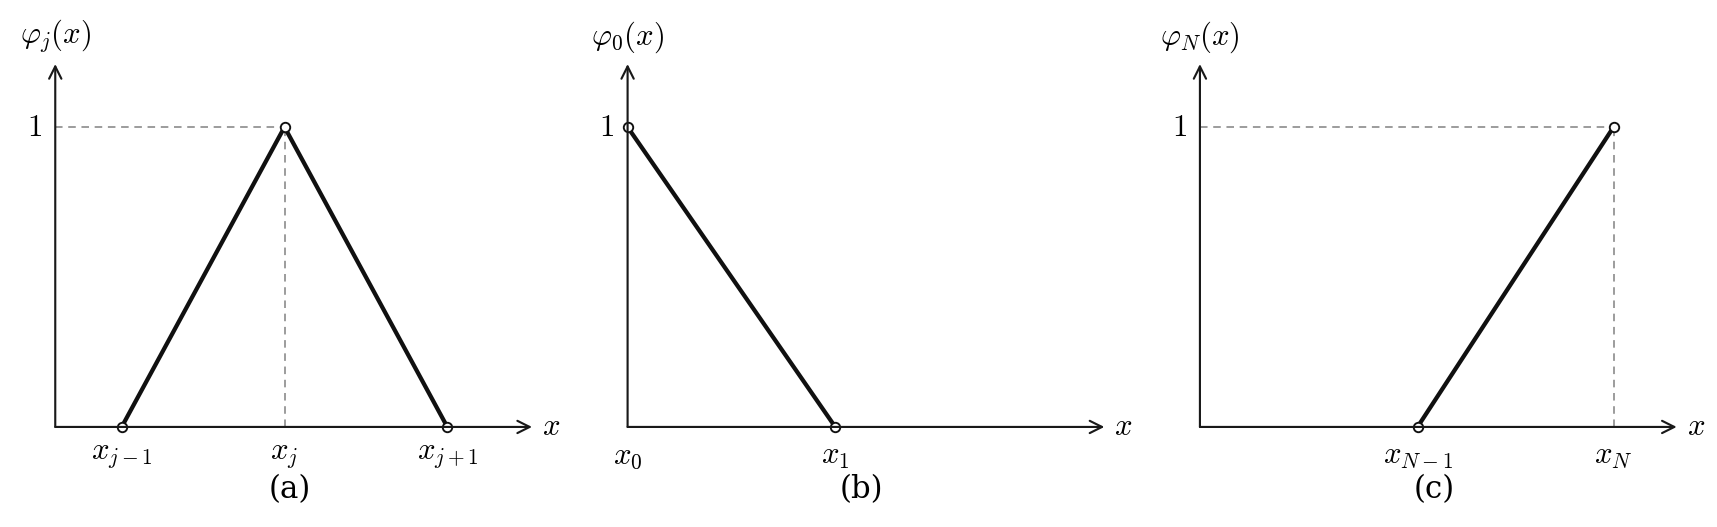

***Рисунок 1.*** *Кусочно линейные базисные функции (a) во внутреннем узле, (b) на левом и (c) на правом конце*

Будем искать приближенное решение

$$
u^N(x)=\sum_{j=0}^N\alpha_j\varphi_j(x). \tag{70}
$$

Так как $\varphi_j(x_i)=\delta_{ij}$, коэффициенты $\alpha_j=u^N(x_j)=u_j^h$ — узловые значения приближения. Поэтому

$$
u^N(x)=\sum_{j=0}^N u_j^h\varphi_j(x). \tag{71}
$$

Носители базисных функций и их производных пересекаются на отрезке ненулевой длины только при $|i-j|\leqslant1$. Поэтому элементы матрицы

$$
a_{ij}=\int_a^b(k\varphi_i'\varphi_j'+q\varphi_i\varphi_j)\,dx \tag{72}
$$

равны нулю при $|i-j|>1$. Внутренние уравнения образуют трехдиагональную систему,

$$
a_{i,i-1}u_{i-1}^h+a_{i,i}u_i^h+a_{i,i+1}u_{i+1}^h=b_i,\quad 1\leqslant i\leqslant N-1, \tag{73}
$$

$$
u_0^h=u_a,\quad u_N^h=u_b. \tag{74}
$$

Вне узлов производная внутренней базисной функции равна

$$
\varphi_j'(x)=
\begin{cases}
1/h_j,&x_{j-1}<x<x_j,\\
-1/h_{j+1},&x_j<x<x_{j+1},\\
0,&\text{иначе}.
\end{cases} \tag{75}
$$

Подстановка производных под интегралы дает

$$
a_{i,i-1}=-\frac{\bar k_{i-1/2}}{h_i}+h_{i+1/2}Q_{i,-}, \tag{76}
$$

$$
a_{i,i+1}=-\frac{\bar k_{i+1/2}}{h_{i+1}}+h_{i+1/2}Q_{i,+}, \tag{77}
$$

$$
\begin{aligned}
a_{i,i}&=\frac{\bar k_{i-1/2}}{h_i}+\frac{\bar k_{i+1/2}}{h_{i+1}}+h_{i+1/2}Q_i,\\
b_i&=h_{i+1/2}F_i,
\end{aligned} \tag{78}
$$

где теплопроводность усредняется арифметически на каждом элементе, а член реакции и правая часть усредняются с весами из базисных функций,

$$
\begin{aligned}
\bar k_{i-1/2}&=\frac1{h_i}\int_{x_{i-1}}^{x_i}k(x)\,dx,\\
Q_{i,\pm}&=\frac1{h_{i+1/2}}\int_{x_{i-1}}^{x_{i+1}}q(x)\varphi_i(x)\varphi_{i\pm1}(x)\,dx,
\end{aligned} \tag{79}
$$

$$
\begin{aligned}
Q_i&=\frac1{h_{i+1/2}}\int_{x_{i-1}}^{x_{i+1}}q(x)\varphi_i^2(x)\,dx,\\
F_i&=\frac1{h_{i+1/2}}\int_{x_{i-1}}^{x_{i+1}}f(x)\varphi_i(x)\,dx.
\end{aligned} \tag{80}
$$

**Определение 9 (проекционно-разностная схема).** Уравнения метода конечных элементов (73), (74) образуют проекционно-разностную схему. По утверждению 2 ее решение единственно. Например, при $k\in C^1[a,b]$, $k\geqslant k_0>0$, ограниченной $q\geqslant0$ и $f\in L^2(a,b)$ кусочно линейное приближение Галеркина с точным вычислением интегралов имеет погрешность $O(h_{\max})$ в $H^1(a,b)$ и $O(h_{\max}^2)$ в $L^2(a,b)$ по энергетической оценке и методу двойственности.

Разделив (73) на $h_{i+1/2}$, получим запись, похожую на консервативную разностную схему (29), (30),

$$
\begin{aligned}
&-\frac1{h_{i+1/2}}\left(\bar k_{i+1/2}\frac{u_{i+1}^h-u_i^h}{h_{i+1}}
-\bar k_{i-1/2}\frac{u_i^h-u_{i-1}^h}{h_i}\right)\\
&\quad + Q_{i,-}u_{i-1}^h+Q_i u_i^h+Q_{i,+}u_{i+1}^h=F_i,\quad 1\leqslant i\leqslant N-1,
\end{aligned} \tag{81}
$$

$$
u_0^h=u_a,\quad u_N^h=u_b. \tag{82}
$$

Схемы отличаются способом усреднения коэффициентов и связью с соседними узлами в члене реакции.

**Замечание 3 (квадратура для гладких коэффициентов).** В простом варианте квадратуры каждый коэффициент заменяют его значением в середине элемента, а базисные множители интегрируют точно. Например,

$$
\int_{x_{i-1}}^{x_i}k(x)\,dx\approx h_i k(x_{i-1/2}), \tag{83}
$$

$$
\int_{x_{i-1}}^{x_i}q(x)\varphi_i(x)\varphi_{i-1}(x)\,dx
\approx \frac{h_i}{6}q(x_{i-1/2}), \tag{84}
$$

$$
\int_{x_{i-1}}^{x_{i+1}}q(x)\varphi_i^2(x)\,dx
\approx \frac{h_i}{3}q(x_{i-1/2})+\frac{h_{i+1}}{3}q(x_{i+1/2}), \tag{85}
$$

$$
\int_{x_i}^{x_{i+1}}q(x)\varphi_i(x)\varphi_{i+1}(x)\,dx
\approx \frac{h_{i+1}}{6}q(x_{i+1/2}). \tag{86}
$$

Тот же прием для правой части дает

$$
b_i\approx f(x_{i-1/2})\int_{x_{i-1}}^{x_i}\varphi_i(x)\,dx
+ f(x_{i+1/2})\int_{x_i}^{x_{i+1}}\varphi_i(x)\,dx, \tag{87}
$$

или

$$
b_i\approx \frac{h_i}{2}f(x_{i-1/2})+\frac{h_{i+1}}{2}f(x_{i+1/2}). \tag{88}
$$

Для произведения соседних базисных функций множитель $1/6$ получается из $\int_0^1 t(1-t)\,dt=1/6$. Остальные веса следуют из интегрирования $t^2$ и $t$. При $k,q,f\in C^2[a,b]$ замена коэффициентов значениями в серединах меняет билинейную и линейную формы на величины порядка $O(h_{\max}^2)$ в нормах $H^1$. Это следует из разложения коэффициентов в середине элемента и обращения в нуль интеграла линейного члена при постоянном тестовом множителе. Указанные порядки погрешности в $H^1$ и $L^2$ сохраняются.

### Специальная проекционно-разностная схема

При разрыве $k$ внутри элемента производная решения может иметь там скачок. В этом случае для обычных кусочно линейных элементов порядки, установленные для гладких коэффициентов, могут не выполняться. Базис, согласованный с коэффициентом диффузии, учитывает поведение потока на каждом элементе.

Пусть $\Delta_j=\int_{x_{j-1}}^{x_j}dy/k(y)$. Внутренние базисные функции имеют вид

$$
\varphi_j(x)=
\begin{cases}
\displaystyle\frac{1}{\Delta_j}\int_{x_{j-1}}^x\frac{dy}{k(y)},&x_{j-1}\leqslant x\leqslant x_j,\\[8pt]
\displaystyle\frac{1}{\Delta_{j+1}}\int_x^{x_{j+1}}\frac{dy}{k(y)},&x_j<x\leqslant x_{j+1},\\[8pt]
0,&\text{иначе}.
\end{cases} \tag{89}
$$

Для граничных функций получаем

$$
\varphi_0(x)=
\begin{cases}
\displaystyle\frac{1}{\Delta_1}\int_x^{x_1}\frac{dy}{k(y)},&x_0\leqslant x\leqslant x_1,\\[8pt]
0,&\text{иначе},
\end{cases} \tag{90}
$$

$$
\varphi_N(x)=
\begin{cases}
\displaystyle\frac{1}{\Delta_N}\int_{x_{N-1}}^x\frac{dy}{k(y)},&x_{N-1}\leqslant x\leqslant x_N,\\[8pt]
0,&\text{иначе}.
\end{cases} \tag{91}
$$

По-прежнему $\varphi_j(x_i)=\delta_{ij}$. Внутри каждого элемента $k\varphi_j'$ постоянна, даже если элемент содержит разрыв коэффициента. Система сохраняет вид (81), (82), а $Q_{i,\pm},Q_i,F_i$ вычисляются в новом базисе. Эффективные коэффициенты теплопроводности теперь определяются гармоническими средними

$$
\kappa_{i-1/2}=\frac{h_i}{\Delta_i},\quad
\kappa_{i+1/2}=\frac{h_{i+1}}{\Delta_{i+1}}, \tag{92}
$$

как в (29), (30). Например, для двух ненулевых базисных функций на $[x_{i-1},x_i]$ величины $k\varphi'$ равны $\pm1/\Delta_i$. Внедиагональный элемент диффузионной части равен $-\int_{x_{i-1}}^{x_i} dx/k(x)\,/\,\Delta_i^2=-1/\Delta_i$. Матрица системы для внутренних узлов трехдиагональная и положительно определенная, поэтому применим метод прогонки.

**Утверждение 3 (точность схемы с согласованным базисом).** Пусть выполняются условия теоремы 1 и интегралы в методе конечных элементов вычисляются точно. Приближение имеет погрешность $O(h_{\max}^2)$ в норме максимума. При $q\equiv0$ получаются точные узловые значения.

**Доказательство.** Пусть $I_hu$ интерполирует точные узловые значения в согласованном базисе. На каждом элементе $k(I_hu)'$ постоянна и равна среднему $ku'$ с весом $1/k$. Поскольку $(ku')'=qu-f$ ограничена, разность между этим средним и $ku'$ на элементе имеет порядок $O(h_i)$. Интегрируя производную $u-I_hu$ от конца элемента, получаем $\|u-I_hu\|_\infty=O(h_{\max}^2)$.

Для каждой согласованной тестовой функции $\varphi_i$ величина $k\varphi_i'$ постоянна на элементе. Поэтому $\int_a^b k(u-I_hu)'\varphi_i'\,dx=0$, так как $u-I_hu$ равна нулю в узлах. В уравнениях для $u^N-I_hu$ остается невязка $\int_a^b q(u-I_hu)\varphi_i\,dx$. Взяв $u^N-I_hu$ в качестве тестовой функции и воспользовавшись коэрцитивностью, получаем $\|(u^N-I_hu)'\|_{L^2}=O(h_{\max}^2)$. Из нулевых краевых значений следует тот же порядок в норме максимума. При $q\equiv0$ невязка обращается в нуль и $u^N=I_hu$. $\square$

Согласованный базис может быть полезен и при гладком коэффициенте теплопроводности, который сильно меняется на одном элементе.

## Литература

1. **Н. Н. Калиткин.** *Численные методы.* М.: Наука, 1978.
2. **А. А. Самарский.** *Теория разностных схем.* 3-е изд. М.: Наука, 1989.
3. **R. J. LeVeque.** *Finite Difference Methods for Ordinary and Partial Differential Equations: Steady-State and Time-Dependent Problems.* SIAM, 2007.
4. **S. C. Brenner, L. R. Scott.** *The Mathematical Theory of Finite Element Methods.* 3rd edition. Springer, 2008.